In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

In [5]:
gen1 = pd.read_csv(RAW/"Plant_1_Generation_Data.csv")
gen2 = pd.read_csv(RAW/"Plant_2_Generation_Data.csv")
w1   = pd.read_csv(RAW/"Plant_1_Weather_Sensor_Data.csv")
w2   = pd.read_csv(RAW/"Plant_2_Weather_Sensor_Data.csv")

gen1["DATE_TIME"] = pd.to_datetime(gen1["DATE_TIME"], format="%d-%m-%Y %H:%M")
for df in (gen2, w1, w2):
    df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

In [6]:
for name, df in [("Gen P1", gen1), ("Gen P2", gen2), ("Weather P1", w1), ("Weather P2", w2)]:
    print(f"--- {name} ---  shape={df.shape}")
    print("nulls:", df.isnull().sum().sum(), "| duplicates:", df.duplicated().sum())
    print("range:", df.DATE_TIME.min(), "->", df.DATE_TIME.max())

# Missing 15-minute intervals
for name, w in [("Plant 1", w1), ("Plant 2", w2)]:
    full = pd.date_range(w.DATE_TIME.min().normalize(), w.DATE_TIME.max().normalize() + pd.Timedelta("23h45min"), freq="15min")
    print(name, "missing weather intervals:", len(full.difference(w.DATE_TIME)))

print(gen1.groupby("SOURCE_KEY").size().describe())   # readings per inverter
gen1.describe().T

--- Gen P1 ---  shape=(68778, 7)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Gen P2 ---  shape=(67698, 7)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Weather P1 ---  shape=(3182, 6)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Weather P2 ---  shape=(3259, 6)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
Plant 1 missing weather intervals: 82
Plant 2 missing weather intervals: 5
count      22.000000
mean     3126.272727
std        10.998623
min      3104.000000
25%      3120.000000
50%      3124.500000
75%      3129.000000
max      3155.000000
dtype: float64


,count,mean,min,25%,50%,75%,max,std
DATE_TIME,68778,2020-06-01 08:02:49.458257,2020-05-15 00:00:00,2020-05-24 00:45:00,2020-06-01 14:30:00,2020-06-09 20:00:00,2020-06-17 23:45:00,NaN
PLANT_ID,68778.0,4135001.0,4135001.0,4135001.0,4135001.0,4135001.0,4135001.0,0.0
DC_POWER,68778.0,3147.426211,0.0,0.0,429.0,6366.964286,14471.125,4036.457169
AC_POWER,68778.0,307.802752,0.0,0.0,41.49375,623.61875,1410.95,394.396439
DAILY_YIELD,68778.0,3295.968737,0.0,0.0,2658.714286,6274.0,9163.0,3145.178309
TOTAL_YIELD,68778.0,6978711.760671,6183645.0,6512002.53575,7146685.0,7268705.90625,7846821.0,416271.982856


In [7]:
cols = ["DATE_TIME", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
m1 = gen1.merge(w1[cols], on="DATE_TIME", how="inner"); m1["PLANT"] = 1
m2 = gen2.merge(w2[cols], on="DATE_TIME", how="inner"); m2["PLANT"] = 2
df = pd.concat([m1, m2], ignore_index=True)
df["HOUR"] = df.DATE_TIME.dt.hour
df["DATE"] = df.DATE_TIME.dt.date
print(df.shape)
df.to_csv(PROC/"merged_raw.csv", index=False)

(136472, 13)


PLANT
1    0.098
2    0.978
dtype: float64


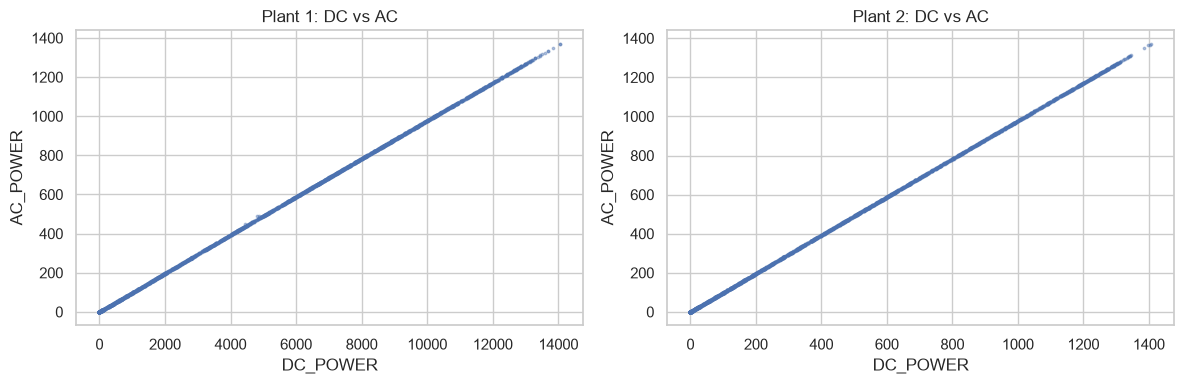

In [8]:
day = df[df.DC_POWER > 0]
print((day.groupby("PLANT").AC_POWER.sum() / day.groupby("PLANT").DC_POWER.sum()).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=False)
for p, a in zip([1, 2], ax):
    s = df[df.PLANT == p].sample(5000, random_state=1)
    a.scatter(s.DC_POWER, s.AC_POWER, s=3, alpha=.4); a.set_title(f"Plant {p}: DC vs AC")
    a.set_xlabel("DC_POWER"); a.set_ylabel("AC_POWER")
plt.tight_layout(); plt.savefig(FIG/"dc_vs_ac.png", dpi=150); plt.show()

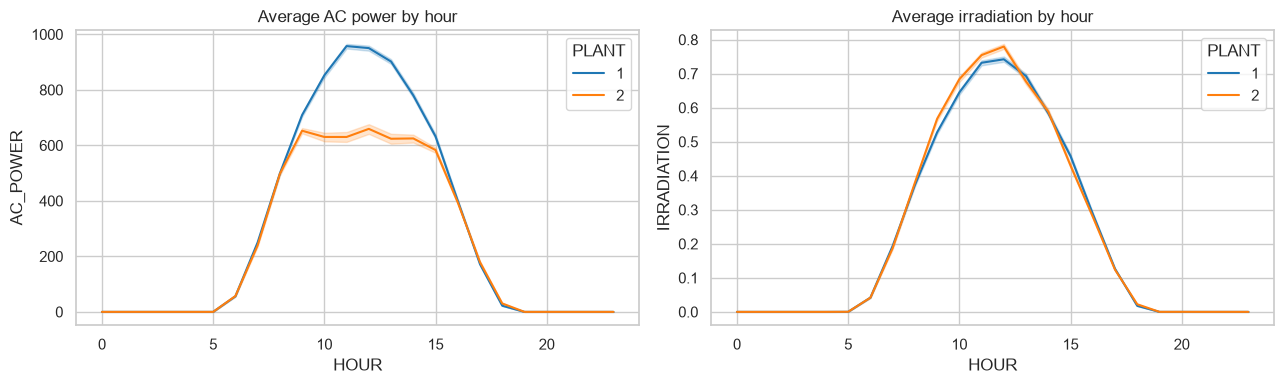

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=df, x="HOUR", y="AC_POWER", hue="PLANT", palette="tab10", ax=ax[0])
ax[0].set_title("Average AC power by hour")
sns.lineplot(data=df, x="HOUR", y="IRRADIATION", hue="PLANT", palette="tab10", ax=ax[1])
ax[1].set_title("Average irradiation by hour")
plt.tight_layout(); plt.savefig(FIG/"hourly_profile.png", dpi=150); plt.show()

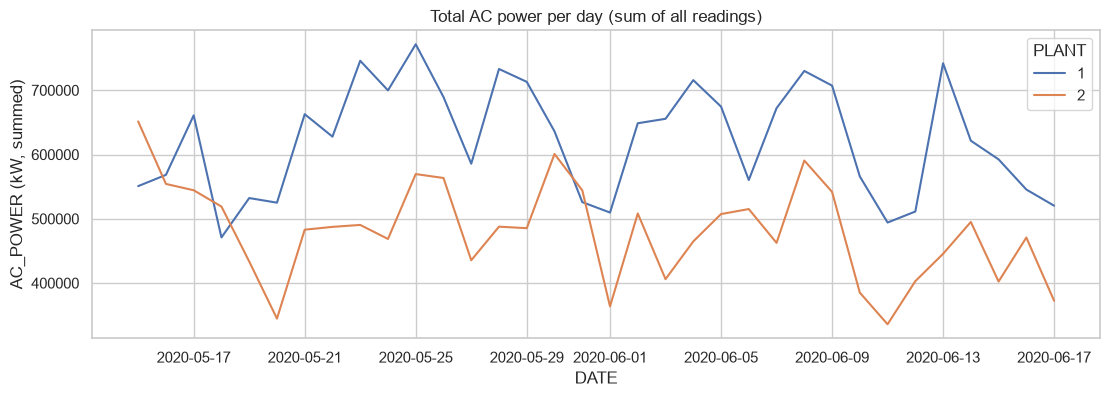

In [10]:
daily = df.groupby(["DATE", "PLANT"]).AC_POWER.sum().unstack()
daily.plot(figsize=(13, 4), title="Total AC power per day (sum of all readings)")
plt.ylabel("AC_POWER (kW, summed)"); plt.savefig(FIG/"daily_total.png", dpi=150); plt.show()

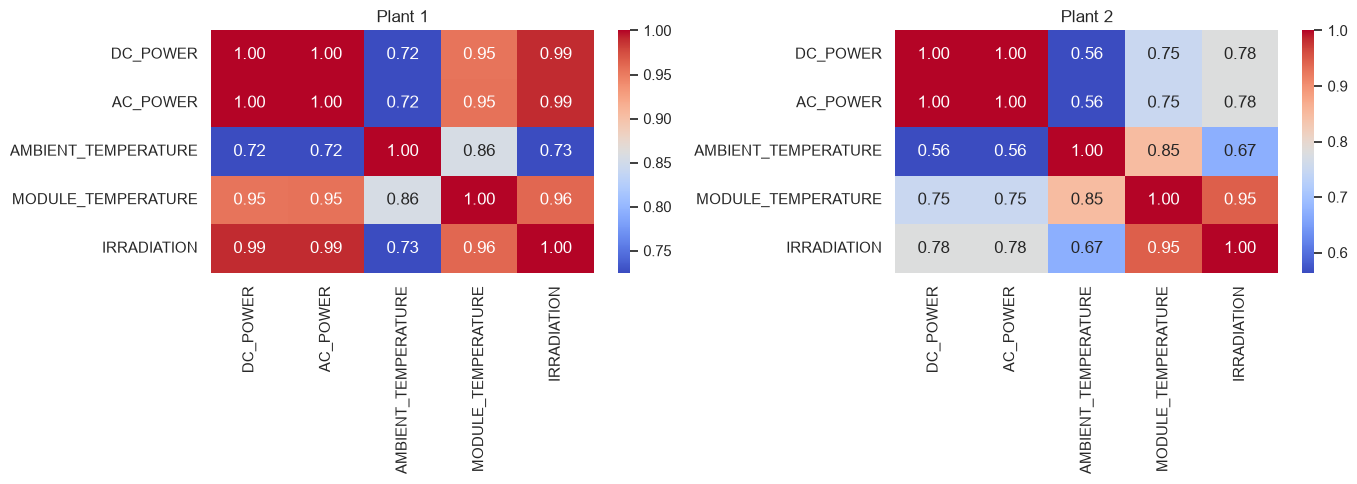

C:\Users\Hridhya\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


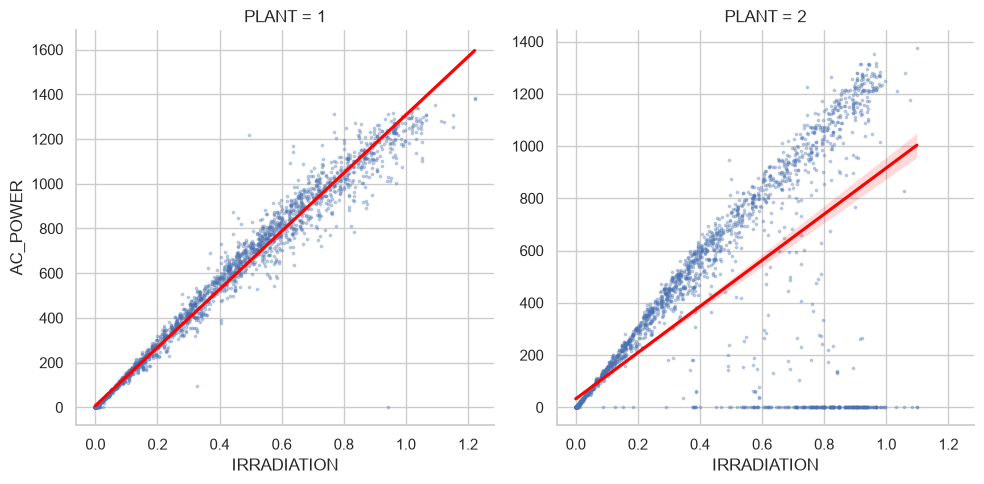

In [11]:
feat = ["DC_POWER", "AC_POWER", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for p, a in zip([1, 2], ax):
    sns.heatmap(df[df.PLANT == p][feat].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=a)
    a.set_title(f"Plant {p}")
plt.tight_layout(); plt.savefig(FIG/"correlation.png", dpi=150); plt.show()

sns.lmplot(data=df.sample(8000, random_state=1), x="IRRADIATION", y="AC_POWER", col="PLANT",
           scatter_kws={"s": 3, "alpha": .3}, line_kws={"color": "red"}, sharey=False)
plt.savefig(FIG/"irradiation_vs_power.png", dpi=150); plt.show()

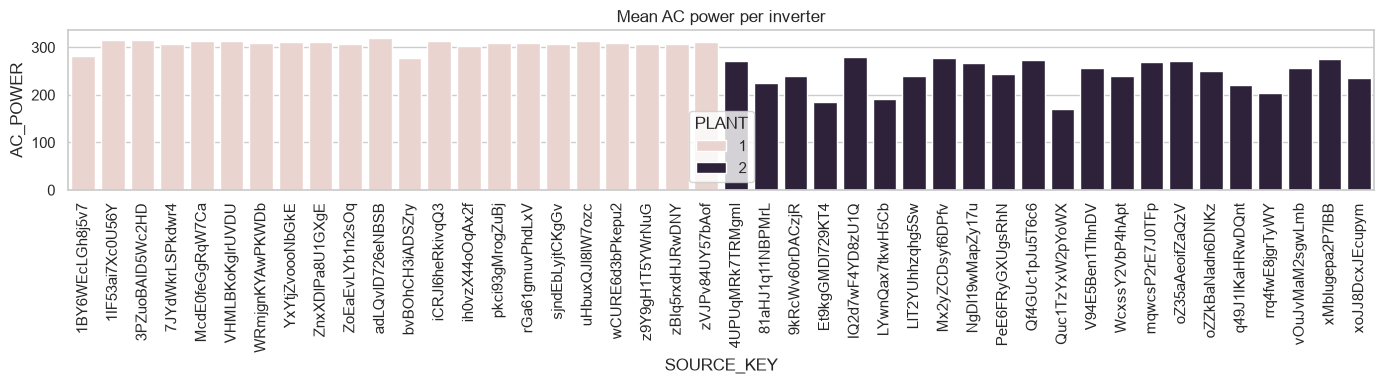

Zero-output rows despite sunlight:
 PLANT
1      62
2    3723
dtype: int64
SOURCE_KEY
LYwnQax7tkwH5Cb    316
Et9kgGMDl729KT4    302
Quc1TzYxW2pYoWX    279
rrq4fwE8jgrTyWY    267
81aHJ1q11NBPMrL    241
q49J1IKaHRwDQnt    239
xoJJ8DcxJEcupym    204
9kRcWv60rDACzjR    203
LlT2YUhhzqhg5Sw    196
WcxssY2VbP4hApt    195
dtype: int64


In [12]:
inv = df.groupby(["PLANT", "SOURCE_KEY"]).AC_POWER.mean().reset_index()
plt.figure(figsize=(14, 4))
sns.barplot(data=inv, x="SOURCE_KEY", y="AC_POWER", hue="PLANT"); plt.xticks(rotation=90)
plt.title("Mean AC power per inverter"); plt.tight_layout()
plt.savefig(FIG/"inverter_comparison.png", dpi=150); plt.show()

fault = df[(df.IRRADIATION > 0.3) & (df.DC_POWER == 0)]
print("Zero-output rows despite sunlight:\n", fault.groupby("PLANT").size())
print(fault[fault.PLANT == 2].groupby("SOURCE_KEY").size().sort_values(ascending=False).head(10))

In [13]:
import json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
PROC, FIG = Path("../data/processed"), Path("../reports/figures")

df = pd.read_csv(PROC/"merged_raw.csv", parse_dates=["DATE_TIME"])
print(df.shape)

(136472, 13)


In [14]:
df.loc[df.PLANT == 1, "DC_POWER"] = df.loc[df.PLANT == 1, "DC_POWER"] / 10

day = df[df.DC_POWER > 0]
print((day.groupby("PLANT").AC_POWER.sum() / day.groupby("PLANT").DC_POWER.sum()).round(3))
# Both plants should now show about 0.978

PLANT
1    0.978
2    0.978
dtype: float64


In [15]:
fault = (df.IRRADIATION > 0.3) & (df.DC_POWER == 0)
print("Fault rows:", fault.groupby(df.PLANT).sum().to_dict(),
      "| total rows:", df.groupby("PLANT").size().to_dict())

clean = df[~fault].copy()

Fault rows: {1: 62, 2: 3723} | total rows: {1: 68774, 2: 67698}


In [16]:
# Night rows are always 0 power, so they would inflate accuracy without adding skill
clean = clean[clean.IRRADIATION > 0].copy()
print(clean.shape)

(73313, 13)


In [17]:
plant = (clean.groupby(["PLANT", "DATE_TIME"])
         .agg(AC_POWER_AVG=("AC_POWER", "mean"),            # mean per healthy inverter (kW)
              IRRADIATION=("IRRADIATION", "first"),         # same value for all inverters
              MODULE_TEMPERATURE=("MODULE_TEMPERATURE", "first"),
              AMBIENT_TEMPERATURE=("AMBIENT_TEMPERATURE", "first"),
              N_INVERTERS=("SOURCE_KEY", "nunique"))
         .reset_index())

print(plant.N_INVERTERS.describe())
plant = plant[plant.N_INVERTERS >= 10].copy()   # drop intervals where too few inverters reported
print(plant.shape)

count    3607.000000
mean       20.325201
std         3.366730
min         3.000000
25%        22.000000
50%        22.000000
75%        22.000000
max        22.000000
Name: N_INVERTERS, dtype: float64
(3564, 7)


In [18]:
t = plant.DATE_TIME.dt
plant["TIME_OF_DAY"] = t.hour + t.minute / 60
plant["TOD_SIN"] = np.sin(2 * np.pi * plant.TIME_OF_DAY / 24)
plant["TOD_COS"] = np.cos(2 * np.pi * plant.TIME_OF_DAY / 24)
plant["TEMP_DIFF"] = plant.MODULE_TEMPERATURE - plant.AMBIENT_TEMPERATURE
plant["PLANT_2"] = (plant.PLANT == 2).astype(int)

plant.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
PLANT,3564.0,1.507856,1.0,1.0,2.0,2.0,2.0,0.500008
DATE_TIME,3564,2020-06-01 04:30:04.040404,2020-05-15 05:45:00,2020-05-23 15:30:00,2020-06-01 09:15:00,2020-06-09 15:15:00,2020-06-17 18:45:00,NaN
AC_POWER_AVG,3564.0,530.609469,0.0,162.975787,516.352638,854.734537,1394.751964,386.297141
IRRADIATION,3564.0,0.404398,0.000001,0.114589,0.383225,0.656176,1.221652,0.30358
MODULE_TEMPERATURE,3564.0,38.845791,18.242308,28.968908,38.410225,48.28319,66.635953,11.31356
AMBIENT_TEMPERATURE,3564.0,28.650506,20.398505,25.69999,28.257634,31.42856,39.181638,3.893545
N_INVERTERS,3564.0,20.487654,10.0,22.0,22.0,22.0,22.0,3.031339
TIME_OF_DAY,3564.0,12.2789,0.0,9.0,12.25,15.75,23.75,3.974952
TOD_SIN,3564.0,-0.037962,-1.0,-0.793353,-0.065403,0.707107,1.0,0.740411
TOD_COS,3564.0,-0.545091,-1.0,-0.896873,-0.608761,-0.258819,1.0,0.391693


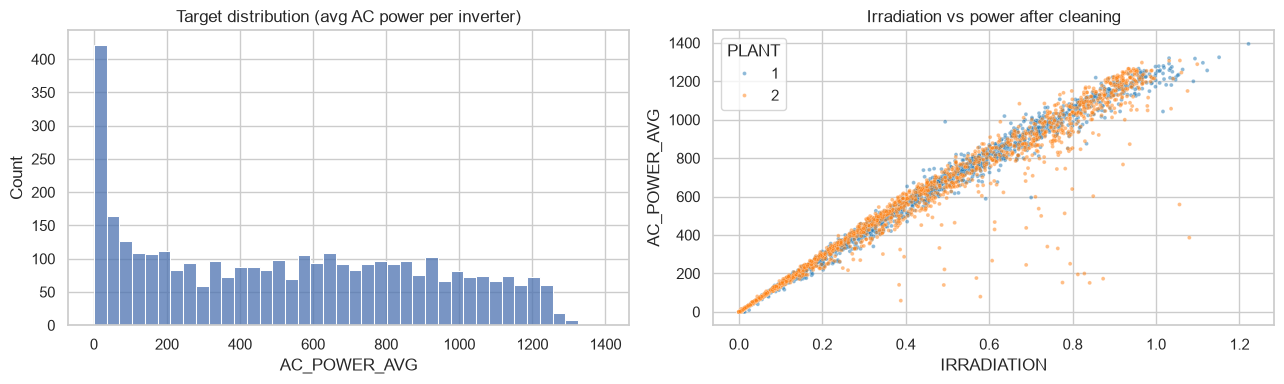

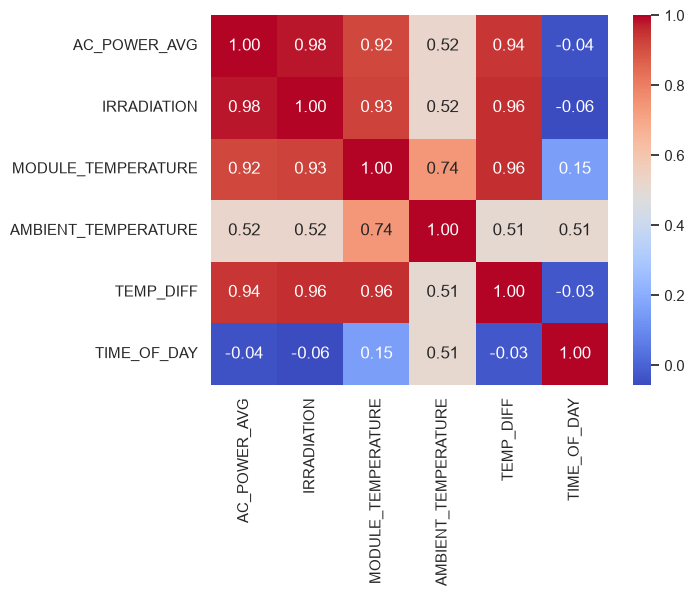

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(plant.AC_POWER_AVG, bins=40, ax=ax[0]); ax[0].set_title("Target distribution (avg AC power per inverter)")
sns.scatterplot(data=plant, x="IRRADIATION", y="AC_POWER_AVG", hue="PLANT", palette="tab10", s=8, alpha=.5, ax=ax[1])
ax[1].set_title("Irradiation vs power after cleaning")
plt.tight_layout(); plt.savefig(FIG/"after_cleaning.png", dpi=150); plt.show()

sns.heatmap(plant[["AC_POWER_AVG", "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF", "TIME_OF_DAY"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.savefig(FIG/"correlation_clean.png", dpi=150); plt.show()

In [20]:
FEATURES = ["IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF", "TOD_SIN", "TOD_COS", "PLANT_2"]
TARGET = "AC_POWER_AVG"

dates = np.sort(plant.DATE_TIME.dt.normalize().unique())
cutoff = dates[-7]
train = plant[plant.DATE_TIME < cutoff]
test  = plant[plant.DATE_TIME >= cutoff]
print("Cutoff:", str(cutoff)[:10], "| train:", train.shape, "| test:", test.shape)

Cutoff: 2020-06-11 | train: (2813, 12) | test: (751, 12)


In [21]:
plant.to_csv(PROC/"plant_level_clean.csv", index=False)
train.to_csv(PROC/"train.csv", index=False)
test.to_csv(PROC/"test.csv", index=False)
json.dump({"features": FEATURES, "target": TARGET, "n_inverters": 22},
          open(PROC/"config.json", "w"), indent=2)